# 02 — Metrics

**What do these numbers mean, and what can they not tell you?**

Read this before any experiment. Several of the metrics we rely on answer a
narrower question than their name suggests, and the difference decides
whether a result is real.

| section | |
|---|---|
| 1 | the catalogue — every metric, by the question it answers, and its blind spot |
| 2 | the SLAs — each target, why that number, which metric proves it |
| 3 | percentiles — why histograms, and when a percentile is not trustworthy |
| 4 | component checks — each component judged by its own metrics |
| 5 | watch them move — own seeded load, with the real Grafana panels |

Independent: drives its own load, needs nothing from 01. Just `make ssh`.


In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, time, random
sys.path.insert(0, '..')

from utils import Cluster, Report, filler
from prom import (Prom, Grafana, CATALOGUE, COMPONENT_CHECKS, LATENCY_HISTOGRAMS,
                  panel_id, panel_queries, metric_name, GRAFANA_URL)
from slos import SLOS, table_rows

cluster = Cluster()
prom    = Prom()
grafana = Grafana(password=os.environ.get('GRAFANA_PASSWORD', ''))
report  = Report('Dodona 02 — metrics', 'what the numbers mean')

report.objective(
    'What does each metric mean, what does good look like, and what can it '
    'NOT tell you?',
    falsified_by='a metric in the catalogue that no longer exists, or a trap '
                 'that no longer reproduces')



Objective
  What does each metric mean, what does good look like, and what can it NOT tell you?
  Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces


Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note='')])

## 0. Generate the traffic this notebook reads

First, so every section below reads data from **this run** rather than
whatever the cluster happened to do earlier. 8 short requests and 4 long
**unique** ones — unique matters, because a repeated prompt is served from
decode's own cache and nothing crosses between pods.

Then one scrape interval, so Prometheus has it.


In [2]:
report.heading('0. Traffic for this run')
random.seed(2)

sent, failed = 0, {}
for i in range(8):
    r = cluster.chat('Reply with the single word: ok', max_tokens=8); sent += 1
    if '_error' in r: failed[r['_error']] = failed.get(r['_error'], 0) + 1
for i in range(4):
    r = cluster.chat(f'[{i}-{random.random()}] ' + filler(4000) + '\n\nReply with: ok',
                     max_tokens=8, timeout=180); sent += 1
    if '_error' in r: failed[r['_error']] = failed.get(r['_error'], 0) + 1

time.sleep(20)   # one scrape interval at 15s
report.table(['', 'count'], [['requests sent', sent],
                            *[[f'refused: {k}', n] for k, n in failed.items()]],
             note='Refusals here are gateway decisions, not GPU limits.')
report.verdict(sent - sum(failed.values()) > 0, 'some traffic completed')
report.conclusion(f'{sent} requests, {sum(failed.values())} refused. Every number '
                  'below covers a 15-minute window that includes this traffic.')



0. Traffic for this run


                 count
  -------------  -----
  requests sent     12
  -- Refusals here are gateway decisions, not GPU limits.
  PASS  some traffic completed

  >> 12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note='')])

## 1. The catalogue

Grouped by the **question**, not the metric name. A name tells you nothing
about whether its value is good.

The last column is the one that matters: **what this metric cannot tell you.**
Twenty of the twenty-three carry one.


In [3]:
# metric name first, then the value, then what it means — a reader needs
# to know WHICH series they would go and look at.
for question, entries in CATALOGUE.items():
    report.heading(question)
    rows = []
    for label, expr, means, blind in entries:
        got = prom.query(expr)
        value = f'{got[0][1]:,.4g}' if got else ('—' if not prom.up() else 'no data')
        rows.append([metric_name(expr), value, label, means])
    report.table(['metric', 'now', 'answers', 'means'], rows)
    for label, expr, _, blind in entries:
        if blind:
            report.text(f'{metric_name(expr)} — CANNOT TELL YOU: {blind}')



Is the GPU busy?


  metric                      now  answers                           means                                                            
  --------------------------  ---  --------------------------------  -----------------------------------------------------------------
  vllm:kv_cache_usage_perc      0  How full is the KV cache?         fraction of a pod's own KV in use — the signal kv_threshold reads
  vllm:num_requests_running     0  How many sequences are resident?  requests the scheduler is stepping right now                     
  vllm:num_requests_waiting     0  Is anything queued?               admitted but not yet running — the scheduler is the limiter      
  vllm:num_preemptions_total    0  Did we overcommit?                the engine evicted a running sequence to fit another             
  vllm:kv_cache_usage_perc — CANNOT TELL YOU: it is a RATIO of that slice. 50% of 4.1 GiB is not 50% of the card.
  vllm:num_requests_running — CANNOT TELL YOU: says nothing about queued wor

  metric                              now      answers                              means                                                   
  ----------------------------------  -------  -----------------------------------  --------------------------------------------------------
  vllm:time_to_first_token_seconds    0.3329   Dead air before the answer starts    TTFT p95 — for a voice agent this is silence            
  vllm:time_per_output_token_seconds  no data  How it reads aloud                   ITL — inter-token latency, the cadence of speech        
  vllm:e2e_request_latency_seconds    0.3663   The whole request                    E2E p95 — what the caller waits                         
  vllm:request_queue_time_seconds     0.3663   Time lost before the GPU touched it  queue p95 — the part admission control is meant to bound
  vllm:time_to_first_token_seconds — CANNOT TELL YOU: a p95 over a 5m window hides a 30s stall that hit three users.
  vllm:time_per_output_token_seconds 

  metric                                                                                        now  answers                          means                                                              
  --------------------------------------------------------------------------------------  ---------  -------------------------------  -------------------------------------------------------------------
  vllm:external_prefix_cache_queries_total{pod=~"vllm-decode.*"}                          1.379e+04  Was the connector asked?         decode looked for blocks on the producer                           
  vllm:external_prefix_cache_hits_total{pod=~"vllm-decode.*"}                             1.379e+04  Did it find blocks?              the LOOKUP matched                                                 
  vllm:prompt_tokens_by_source_total{source="external_kv_transfer",pod=~"vllm-decode.*"}  1.379e+04  Did bytes actually arrive?       prompt tokens whose KV came over the wire instead of being

  metric                now  answers                means                          
  --------------------  ---  ---------------------  -------------------------------
  orch_requests_total    27  How much arrived?      requests past guardrails       
  orch_completed_total   27  How much was served?   completions                    
  orch_shed_total         0  How much was refused?  shed, by why                   
  orch_overflow_total     0  Did anything leave?    bursted to an external provider
  orch_shed_total — CANNOT TELL YOU: a 429 is the tenant over quota; a 503 is capacity. Reporting them together makes a quota limit look like a GPU limit.
  orch_overflow_total — CANNOT TELL YOU: capped for the process lifetime, so 0 can mean 'never needed' or 'budget already spent'.

Is routing choosing well?


  metric                            now  answers                     means                                
  --------------------------------  ---  --------------------------  -------------------------------------
  orch_pick_total                    54  How many placements?        a pod was chosen                     
  orch_sticky_total                   0  How many were prefix-warm?  placed where the prefix already lives
  orch_pick_unknown_snapshot_total    0  How many were blind?        chosen with no usable signal         
  orch_sticky_total — CANNOT TELL YOU: only meaningful against the total — 10 sticky of 10 is perfect, of 1000 is noise.
  orch_pick_unknown_snapshot_total — CANNOT TELL YOU: high here means the scorers are inert and placement is effectively random, whatever the policy says.

Is the autoscaler awake?


  metric                                                     now  answers              means                      
  ---------------------------------------------------------  ---  -------------------  ---------------------------
  keda_scaler_metrics_value                                    0  What does KEDA see?  the value its trigger reads
  kube_deployment_status_replicas{deployment="vllm-decode"}    1  What has it done?    actual replicas            
  keda_scaler_metrics_value — CANNOT TELL YOU: it polls — it lags the real signal.
  kube_deployment_status_replicas{deployment="vllm-decode"} — CANNOT TELL YOU: scaling UP takes minutes on a pod that loads weights; the metric moves long before capacity does.


## 2. The SLAs

A measurement is a number. A measurement against a promise is a result.

These live in `benchmarking/slos.py`, so every notebook checks the same ones
and nothing drifts between documents.


In [4]:
report.heading('2. The SLAs')
rows = []
for key, s in SLOS.items():
    rows.append([s.label, f'{s.target:g}{s.unit}', s.why])
report.table(['promise', 'target', 'why that number'], rows)
report.text('Concurrency is deliberately absent: it is derived in 03-capacity '
            'from a measured saturation curve. A concurrency target picked '
            'before measuring is a wish.')
report.conclusion(
    'Each has a metric that proves it: TTFT and turn from the latency '
    'histograms, preemptions from vllm:num_preemptions_total, shed rate from '
    'orch_shed_total over orch_requests_total.')



2. The SLAs
  promise                   target  why that number                                                                                                                
  ------------------------  ------  -------------------------------------------------------------------------------------------------------------------------------
  TTFT p95                  1.5s    A voice agent's latency is dead air. Past about 1.5s the listener starts talking over it.                                      
  turn p95                  30s     A research turn runs tool calls and reads sources. 30s is the budget for the whole turn, not one forward pass.                 
  preemptions               0       vLLM preempting a sequence is a stall mid-sentence in a spoken answer. This is the failure admission control exists to prevent.
  shed rate at target load  0.05    503s are allowed but rare. Shedding early beats preempting; a system shedding 30% is not serving.                              
  C

Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0', 'How full is the K

## 3. Percentiles

vLLM publishes **histograms**. The percentile comes from the buckets:

```promql
histogram_quantile(0.99, sum by (le) (rate(vllm:time_to_first_token_seconds_bucket[5m])))
```

Sorting ten samples in Python gives a "p99" that is the maximum of ten and
swings wildly between runs. This notebook did that until recently.

**What each hides from the others:** p50 is the typical experience and says
nothing about the tail. p99 is the tail and says nothing about how common it
is. A p50 of 0.3s with a p99 of 8s is a system that works until it doesn't.



3. Percentiles


  metric    n  mean s   p50 s   p90 s   p99 s  lowest le  in it
  -------  --  ------  ------  ------  ------  ---------  -----
  ttft     54  0.0885  0.0553  0.2091  0.4666      0.001     0%
  e2e      54  0.0934  0.1622  0.2919  0.4733        0.3    93%
  queue    54  0.0377  0.1622  0.2919  0.4733        0.3    93%
  prefill  54  0.0351  0.1500  0.2700  0.2970        0.3   100%
  decode   54  0.0050  0.1500  0.2700  0.2970        0.3   100%
  -- mean is exact (_sum/_count). The last two columns say whether the percentiles mean anything.


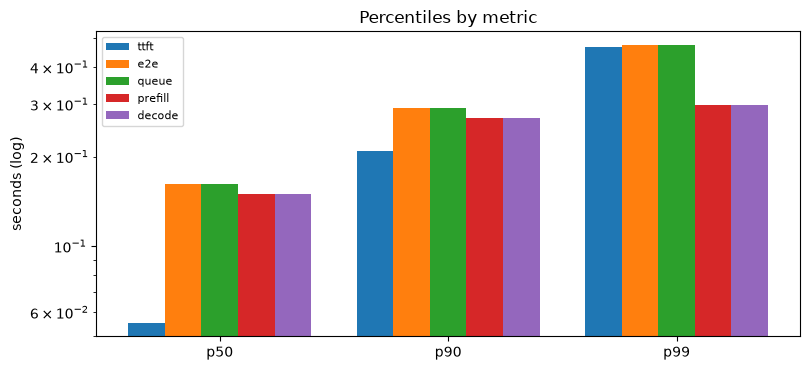

  FAIL  every histogram has data spread across its buckets
  e2e: 93% of samples are below the lowest bucket edge (0.3s), and the true mean is 0.0934s.
  queue: 93% of samples are below the lowest bucket edge (0.3s), and the true mean is 0.0377s.
  prefill: 100% of samples are below the lowest bucket edge (0.3s), and the true mean is 0.0351s.
  decode: 100% of samples are below the lowest bucket edge (0.3s), and the true mean is 0.0050s.

  >> vLLM's histograms start at le=0.3s and every request here finishes well inside that, so histogram_quantile interpolates within [0, 0.3] and returns the same p50/p90/p99 for any metric whose data is entirely below it. That is why e2e, queue, prefill and decode read identically while their means differ by 17x. MORE LOAD DOES NOT FIX THIS — only slower requests or a finer bucket layout would. At this latency quote the mean, or use TTFT, whose buckets start at 0.001s.



In [5]:
report.heading('3. Percentiles')
cell = lambda x: f'{x:.4f}' if x is not None else '—'
rows, series, saturated = [], {}, []
for name in ('ttft', 'tpot', 'e2e', 'queue', 'prefill', 'decode'):
    q, stats = prom.quantiles(name, qs=(0.5, 0.9, 0.99)), prom.histogram_stats(name)
    if not q and not stats:
        continue
    # How much of the data sits in the histogram's LOWEST bucket. If all
    # of it does, every quantile is an interpolation inside that one
    # bucket and carries no information about the real distribution.
    b = prom.bucket_saturation(name)
    frac = b.get('fraction_in_lowest', 0)
    if frac > 0.9:
        saturated.append((name, b.get('lowest_edge'), frac, stats.get('mean', 0)))
    rows.append([name, f"{stats.get('count', 0):,.0f}",
                 f"{stats.get('mean', 0):.4f}",
                 cell(q.get(0.5)), cell(q.get(0.9)), cell(q.get(0.99)),
                 f"{b.get('lowest_edge', 0):g}", f'{frac:.0%}'])
    if q:
        series[name] = [q.get(0.5, 0), q.get(0.9, 0), q.get(0.99, 0)]

if rows:
    report.table(['metric', 'n', 'mean s', 'p50 s', 'p90 s', 'p99 s',
                  'lowest le', 'in it'], rows,
                 note='mean is exact (_sum/_count). The last two columns say '
                      'whether the percentiles mean anything.')
    report.bar('Percentiles by metric', ['p50', 'p90', 'p99'], series,
               ylabel='seconds (log)', log=True)

    report.verdict(not saturated,
                   'every histogram has data spread across its buckets')
    for name, edge, frac, mean in saturated:
        report.text(f'{name}: {frac:.0%} of samples are below the lowest bucket '
                    f'edge ({edge:g}s), and the true mean is {mean:.4f}s.')
    if saturated:
        edge = saturated[0][1]
        report.conclusion(
            f'vLLM\'s histograms start at le={edge:g}s and every request here finishes '
            f'well inside that, so histogram_quantile interpolates within [0, {edge:g}] '
            'and returns the same p50/p90/p99 for any metric whose data is '
            'entirely below it. That is why e2e, queue, prefill and decode read '
            'identically while their means differ by 17x. MORE LOAD DOES NOT FIX '
            'THIS — only slower requests or a finer bucket layout would. At this '
            'latency quote the mean, or use TTFT, whose buckets start at 0.001s.')
    else:
        report.conclusion('Buckets are populated, so the percentiles carry '
                          'information about the distribution.')
else:
    report.text('No histogram data yet.')


## 4. Component checks

Each component, its own metrics, and a verdict. First principles: what is
this component supposed to do, which number says whether it did it.

The *cannot tell you* column in section 1 is what keeps these honest — several
of these metrics answer a narrower question than their name suggests.


In [6]:
report.heading('4. Component checks')
v = lambda expr: (prom.query(expr)[0][1] if prom.query(expr) else 0.0)

for group, checks in COMPONENT_CHECKS.items():
    report.heading(group)
    rows = []
    for label, expr, meaning in checks:
        got = prom.query(expr)
        value = f'{got[0][1]:,.4g}' if got else 'no data'
        rows.append([metric_name(expr), value, meaning])
    report.table(['metric', 'value', 'what it means'], rows)



4. Component checks

prefill / decode roles


  metric                                                   value  what it means                            
  ---------------------------------------------------  ---------  -----------------------------------------
  vllm:prompt_tokens_total{pod=~"vllm-prefill.*"}      2.808e+04  prefill should carry prompt work         
  vllm:generation_tokens_total{pod=~"vllm-prefill.*"}         27  near 0: its leg is sent with max_tokens=1
  vllm:generation_tokens_total{pod=~"vllm-decode.*"}          54  decode does the generating               

scheduler


  metric                      value  what it means                              
  --------------------------  -----  -------------------------------------------
  vllm:num_requests_running       0  in flight on the GPU                       
  vllm:num_requests_waiting       0  queued behind max-num-seqs                 
  vllm:num_preemptions_total      0  must be 0 — a preempt is a stall mid-answer
  vllm:kv_cache_usage_perc        0  the signal admission reads                 

KV hop


  metric                                                                                      value  what it means                            
  --------------------------------------------------------------------------------------  ---------  -----------------------------------------
  vllm:external_prefix_cache_queries_total{pod=~"vllm-decode.*"}                          1.379e+04  decode looked for remote blocks          
  vllm:external_prefix_cache_hits_total{pod=~"vllm-decode.*"}                             1.379e+04  blocks found remotely                    
  vllm:prompt_tokens_by_source_total{source="external_kv_transfer",pod=~"vllm-decode.*"}  1.379e+04  KV that arrived instead of being computed
  vllm:prompt_tokens_by_source_total{source="local_compute",pod=~"vllm-decode.*"}                 0  prompt work decode had to do itself      
  orch_kv_transfer_total                                                                         27  router bookkeeping — not proof of bytes  

  metric                value  what it means           
  --------------------  -----  ------------------------
  orch_requests_total      27  reached the gateway     
  orch_completed_total     27  served                  
  orch_shed_total           0  refused, by reason below
  orch_overflow_total       0  bursted to a provider   

routing


  metric                            value  what it means                          
  --------------------------------  -----  ---------------------------------------
  orch_pick_total                      54  a pod was chosen                       
  orch_sticky_total                     0  placed on a prefix-warm pod            
  orch_pick_unknown_snapshot_total      0  placed blind — the scorer had no signal

KEDA
====


  metric                                                     value  what it means            
  ---------------------------------------------------------  -----  -------------------------
  keda_scaler_metrics_value                                      0  what KEDA sees           
  kube_deployment_status_replicas{deployment="vllm-decode"}      1  what it has done about it


### 4.1 The KV connector

It exists to let decode load the prompt's KV from prefill instead of
recomputing it. Three numbers, in the order the request passes through them:
**asked → found → arrived.**

`external_prefix_cache_hits_total` records that the *lookup* matched. The
pull happens after, and can fail. So `found` and `arrived` agreeing is what
says the connector is doing its job end to end.



4.1 The KV connector


  stage    tokens                                          
  -------  ------  ----------------------------------------
  asked    13,787  decode looked for blocks on the producer
  found    13,787  the lookup matched                      
  arrived  13,787  KV that came over the wire              
  PASS  the connector has delivered KV
  PASS  found and arrived agree — lookups are completing as transfers


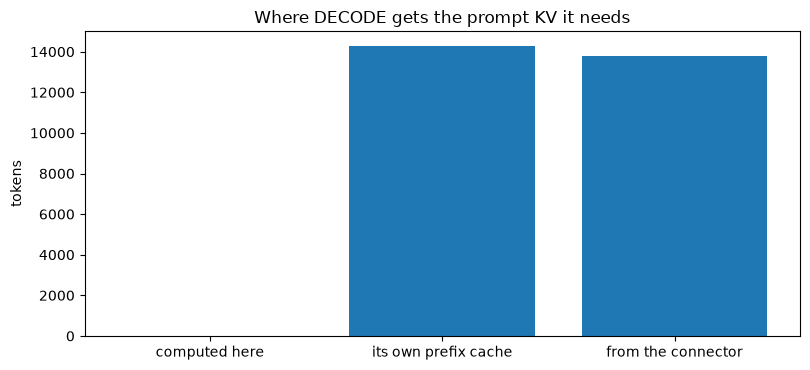

  how to read it: the first two are local to decode; only the third crossed between pods
  PASS  decode recomputes 0.0% of its prompt tokens

  >> Of 28,075 prompt tokens decode needed, 13,787 (49.1%) arrived as KV from prefill, 14,288 came from its own prefix cache, and it computed 0. Decode does no prompt work at all — the hop is carrying the whole prompt, which is exactly what disaggregation is for.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0', 'How full is the K

In [7]:
report.heading('4.1 The KV connector')
# Scoped to decode. BOTH pools run a connector, so an unscoped sum counts
# prefill's queries too and credits prefill's own prompt work to decode —
# which made a perfect hop read as 'half of it was recomputed'.
D = '{pod=~"vllm-decode.*"}'
S = lambda src: ('sum(vllm:prompt_tokens_by_source_total'
                 f'{{source="{src}",pod=~"vllm-decode.*"}})')
asked    = v(f'sum(vllm:external_prefix_cache_queries_total{D})')
found    = v(f'sum(vllm:external_prefix_cache_hits_total{D})')
arrived  = v(S('external_kv_transfer'))
computed = v(S('local_compute'))
cached   = v(S('local_cache_hit'))

report.table(['stage', 'tokens', ''], [
    ['asked',   f'{asked:,.0f}',   'decode looked for blocks on the producer'],
    ['found',   f'{found:,.0f}',   'the lookup matched'],
    ['arrived', f'{arrived:,.0f}', 'KV that came over the wire'],
])
report.verdict(arrived > 0, 'the connector has delivered KV')
report.verdict(abs(found - arrived) < max(found, 1) * 0.1,
               'found and arrived agree — lookups are completing as transfers')

report.bar('Where DECODE gets the prompt KV it needs',
           ['computed here', 'its own prefix cache', 'from the connector'],
           {'prompt tokens': [computed, cached, arrived]}, ylabel='tokens',
           note='the first two are local to decode; only the third crossed between pods')

total = computed + cached + arrived
report.verdict(total == 0 or computed / total < 0.1,
               f'decode recomputes {computed/max(total,1):.1%} of its prompt tokens')
report.conclusion(
    f'Of {total:,.0f} prompt tokens decode needed, {arrived:,.0f} '
    f'({arrived/max(total,1):.1%}) arrived as KV from prefill, {cached:,.0f} came '
    f'from its own prefix cache, and it computed {computed:,.0f}. '
    + ('Decode does no prompt work at all — the hop is carrying the whole '
       'prompt, which is exactly what disaggregation is for.'
       if computed == 0 else 'The rest it had to compute itself.')
    if arrived > 0 else
    f'None of the {total:,.0f} prompt tokens came from the connector. '
    + (f'It was asked {asked:,.0f} times and found {found:,.0f}, so the lookup '
       'works and the transfer does not — check `make kv`.'
       if found > 0 else 'It found nothing, so there was nothing to transfer.'))


### 4.2 Prefill and decode are doing different jobs

The split is only real if the two pools behave differently. Prefill's leg is
sent with `max_tokens=1`: enough to build the prompt's KV, not to answer.
So prefill should emit **one token per request** and decode should do the
generating.


In [8]:
report.heading('4.2 Prefill and decode')
# Over ONE window, not raw totals. orch_requests_total resets when
# orch-serve restarts — which it does on every `make cluster` — while the
# vLLM pods are hours older. Dividing one by the other mixes two different
# time origins and reported 5.24 tokens per request for a max_tokens=1 leg.
W = '1h'
pre_gen = v(f'sum(increase(vllm:generation_tokens_total{{pod=~"vllm-prefill.*"}}[{W}]))')
dec_gen = v(f'sum(increase(vllm:generation_tokens_total{{pod=~"vllm-decode.*"}}[{W}]))')
pre_req = v(f'sum(increase(vllm:request_success_total{{pod=~"vllm-prefill.*"}}[{W}]))')
per_req = pre_gen / pre_req if pre_req else 0

report.table(['', f'last {W}', ''], [
    ['prefill requests',  f'{pre_req:,.0f}', 'its leg of each split'],
    ['prefill generated', f'{pre_gen:,.0f}', f'{per_req:.2f} tokens per request'],
    ['decode generated',  f'{dec_gen:,.0f}', 'the actual answers'],
], note='Both from the same window and the same pods, so the ratio is real.')
report.verdict(pre_req == 0 or per_req < 1.5,
               f'prefill emits {per_req:.2f} tokens per request (max_tokens=1 '
               'means ~1.0)')
report.conclusion(
    f'Over the last {W} prefill answered {pre_req:,.0f} requests with '
    f'{pre_gen:,.0f} tokens — {per_req:.2f} each, which is the max_tokens=1 leg '
    f'doing prompt work only, against decode\'s {dec_gen:,.0f}. The two pools '
    'are doing different jobs.'
    if per_req < 1.5 else
    f'Prefill emitted {per_req:.2f} tokens per request. A max_tokens=1 leg '
    'cannot do that, so both legs are sending the full request — check '
    'LAB_SPLIT and queue.py.')



4.2 Prefill and decode


                     last 1h                         
  -----------------  -------  -----------------------
  prefill requests        77  its leg of each split  
  prefill generated       77  1.00 tokens per request
  decode generated       153  the actual answers     
  -- Both from the same window and the same pods, so the ratio is real.
  PASS  prefill emits 1.00 tokens per request (max_tokens=1 means ~1.0)

  >> Over the last 1h prefill answered 77 requests with 77 tokens — 1.00 each, which is the max_tokens=1 leg doing prompt work only, against decode's 153. The two pools are doing different jobs.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0', 'How full is the K

### 4.3 The slice, not the card

`kv_cache_usage_perc` is a ratio of **one pod's own** KV. On this cluster each
pod has a 12 GiB HAMi slice, not the whole card — so the absolute numbers
differ by about 15x and only one of them is the right denominator.


In [9]:
report.heading('4.3 Slice capacity')
KV_GIB, SEQ_PER_POD = 4.10, 4.7
# The peak over an hour, not the instant. An idle reading makes the whole
# section a tautology: 0% of a slice is 0 GiB, which says nothing.
peak = v('max(max_over_time(vllm:kv_cache_usage_perc[1h]))')
now  = v('max(vllm:kv_cache_usage_perc)')

report.table(['', 'KV available', 'full-length sequences @16k'], [
    ['the whole H100', '~64 GiB', '~73.5'],
    ['one 12 GiB HAMi slice', f'{KV_GIB:.2f} GiB', f'{SEQ_PER_POD:.1f}'],
], note='CUDA-graph capture scales with available memory, so the whole-card '
        'figure cannot be divided down — it is measured per slice.')
report.table(['kv_cache_usage_perc', 'ratio', 'of this slice'], [
    ['now', f'{now:.1%}', f'{now*KV_GIB:.2f} GiB'],
    ['peak over 1h', f'{peak:.1%}', f'{peak*KV_GIB:.2f} GiB'],
])
report.verdict(peak < 0.90,
               f'KV peaked at {peak:.1%} — below the 0.90 admission threshold')
report.conclusion(
    f'A pod holds {KV_GIB:.2f} GiB of KV, which is {SEQ_PER_POD:.1f} full-length '
    f'sequences — that is the denominator for every concurrency claim, and it is '
    f'15x smaller than the whole card would suggest. Over the last hour KV peaked '
    f'at {peak:.1%} ({peak*KV_GIB:.2f} GiB), so '
    + ('the admission threshold was reachable.' if peak >= 0.90 else
       'a kv_threshold policy had nothing to decide. Making it bind is what '
       '03-capacity is for.'))



4.3 Slice capacity


                         KV available  full-length sequences @16k
  ---------------------  ------------  --------------------------
  the whole H100         ~64 GiB       ~73.5                     
  one 12 GiB HAMi slice  4.10 GiB      4.7                       
  -- CUDA-graph capture scales with available memory, so the whole-card figure cannot be divided down — it is measured per slice.
  kv_cache_usage_perc  ratio  of this slice
  -------------------  -----  -------------
  now                   0.0%       0.00 GiB
  peak over 1h          0.0%       0.00 GiB
  PASS  KV peaked at 0.0% — below the 0.90 admission threshold

  >> A pod holds 4.10 GiB of KV, which is 4.7 full-length sequences — that is the denominator for every concurrency claim, and it is 15x smaller than the whole card would suggest. Over the last hour KV peaked at 0.0% (0.00 GiB), so a kv_threshold policy had nothing to decide. Making it bind is what 03-capacity is for.



Report(title='Dodona 02 — metrics', subtitle='what the numbers mean', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='What does each metric mean, what does good look like, and what can it NOT tell you?', note=''), _Block(kind='text', payload='Falsified by: a metric in the catalogue that no longer exists, or a trap that no longer reproduces', note=''), _Block(kind='heading', payload='0. Traffic for this run', note=''), _Block(kind='table', payload=(['', 'count'], [['requests sent', 12]]), note='Refusals here are gateway decisions, not GPU limits.'), _Block(kind='verdict', payload=(True, 'some traffic completed'), note=''), _Block(kind='conclusion', payload='12 requests, 0 refused. Every number below covers a 15-minute window that includes this traffic.', note=''), _Block(kind='heading', payload='Is the GPU busy?', note=''), _Block(kind='table', payload=(['metric', 'now', 'answers', 'means'], [['vllm:kv_cache_usage_perc', '0', 'How full is the K

## 5. The same numbers, as Grafana draws them

Rendered server-side, not redrawn — a screenshot of the panel the team
already watches needs no explanation of how it was derived.

Needs `GRAFANA_PASSWORD` and the renderer deployment; falls back to links.


In [10]:
from pathlib import Path
shots = Path('screenshots'); shots.mkdir(exist_ok=True)
wanted = [('dodona-vllm', 'vllm', 'GPU KV cache'), ('dodona-vllm', 'vllm', 'TTFT'),
          ('dodona-mooncake', 'mooncake', 'DELIVERED'),
          ('dodona-mooncake', 'mooncake', 'Claimed vs delivered'),
          ('dodona-gateway', 'gateway', 'shed')]
saved = []
for uid, dash, title in wanted:
    pid = panel_id(dash, title)
    if pid is None: continue
    out = grafana.render(uid, pid, shots / f'{dash}-{title[:18].lower().replace(" ","-")}.png')
    if out: saved.append(out)

if saved:
    report.verdict(True, f'rendered {len(saved)} Grafana panels')
    from IPython.display import Image, display
    for s in saved: display(Image(filename=str(s)))
else:
    report.text('No panels rendered — set GRAFANA_PASSWORD (printed by '
                'make observability) and check renderer.yaml is deployed.')
    report.links([(d, f'{GRAFANA_URL}/d/{u}?from=now-30m&to=now')
                  for u, d in dict.fromkeys((u, d) for u, d, _ in wanted)])


  No panels rendered — set GRAFANA_PASSWORD (printed by make observability) and check renderer.yaml is deployed.


- [vllm](http://127.0.0.1:31495/d/dodona-vllm?from=now-30m&to=now)
- [mooncake](http://127.0.0.1:31495/d/dodona-mooncake?from=now-30m&to=now)
- [gateway](http://127.0.0.1:31495/d/dodona-gateway?from=now-30m&to=now)

## Save


In [11]:
path  = report.save('02-metrics')
fails = report.failures()
print('wrote', path)
print()
if fails:
    for f in fails: print('  open:', f)
else:
    print('Every metric accounted for. Next: 03-capacity')


wrote /Users/harshuljain/work/projects/experiments_and_courses/llm-inference/dodona/benchmarking/02-metrics/reports/02-metrics.pdf

  open: every histogram has data spread across its buckets
